# 5장 · 머신러닝의 기본 요소 (일반화)

『케라스 창시자에게 배우는 딥러닝 개정 3판』 5장을 **돌려 보면서 설명하는** 스터디용 노트북이에요.
위에서부터 차례로 실행하면 돼요. CPU로 전체 실행 약 5~10분.

| 절 | 실험 | 그림 노트 카드 · 내 필기 |
|---|---|---|
| 1 | 노이즈 특성을 붙이면 검증 정확도가 떨어진다 | 5.1 과소적합 vs 과대적합 |
| 2 | 레이블을 섞어도 훈련 정확도는 오른다 (= 외우기) | 5.1 과소적합 vs 과대적합 |
| 3 | 픽셀 공간 vs 매니폴드: 두 숫자의 평균은 숫자가 아니다 | 5.1.2 매니폴드 가설과 보간 |
| 4 | 홀드아웃 · K-겹 · 상식 수준 기준점 · 정보 누설 | 5.2 훈련 · 검증 · 테스트 |
| 5 | 학습률이 너무 크면 / 모델이 너무 작으면 | 5.3 훈련 성능 향상: 증상 → 처방 |
| 6 | IMDB로 작은 모델 · L2 · 드롭아웃 비교 | 5.4 일반화 성능 향상 (규제) |

**스터디 진행 방법**
- 🔍 **내부 들여다보기** 셀: 모델 안의 가중치 · 텐서 · 손실 값을 직접 꺼내 보는 셀이에요. 여기서 멈추고 설명하기 좋아요.
- 💬 **설명 포인트**: 발표자가 말로 짚을 질문이에요. 답은 바로 아래 접힌 줄에 있어요.

## 0. 준비

- `KERAS_BACKEND`는 **`import keras` 전에** 정해요. 바꾸려면 커널 재시작 → 이 셀부터 다시.
- 시드를 고정해서 실행할 때마다 거의 같은 결과가 나오게 해요 (CPU 연산 순서 때문에 소수점 끝자리는 조금 달라질 수 있어요).

In [1]:
import os
os.environ["KERAS_BACKEND"] = "jax"   # "tensorflow" / "torch" / "jax"

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)
plt.rcParams["font.family"] = "Malgun Gothic"     # 그래프 한글 깨짐 방지 (윈도)
plt.rcParams["axes.unicode_minus"] = False
print("keras", keras.__version__, "| backend =", keras.backend.backend())

keras 3.15.1 | backend = jax

In [2]:
def plot_history(histories, key="val_loss", title=None, ylim=None):
    """여러 history를 한 그래프에 겹쳐 그리기. histories = {"이름": history}"""
    plt.figure(figsize=(7, 3.6))
    for name, h in histories.items():
        v = h.history[key]
        plt.plot(range(1, len(v) + 1), v, "-o", ms=3, label=name)
    plt.xlabel("에포크"); plt.ylabel(key); plt.title(title or key)
    if ylim: plt.ylim(*ylim)
    plt.legend(); plt.grid(alpha=.3); plt.show()

### 공통 데이터: MNIST

- 28×28 이미지를 784 벡터로 펴고, 0~1로 스케일링해요 (2장과 같음).

In [3]:
from keras.datasets import mnist

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = train_images.reshape((60000, 28 * 28)).astype("float32") / 255
test_images = test_images.reshape((10000, 28 * 28)).astype("float32") / 255
print("train", train_images.shape, "test", test_images.shape)
print("픽셀 범위:", train_images.min(), "~", train_images.max())

train (60000, 784) test (10000, 784)
픽셀 범위: 0.0 ~ 1.0

## 1. 잡음 특성이 일반화를 망친다 (§5.1)

**실험**: 784개 픽셀 옆에 784개를 더 붙여요.
- 모델 A: **백색 잡음**(랜덤 숫자) 784개를 붙임
- 모델 B: **0** 784개를 붙임 (정보도 없고 방해도 없음)

입력 크기는 둘 다 1568로 같아요. 차이는 '쓸모없는데 그럴듯해 보이는 특성'이 있느냐 하나뿐이에요.

(60000, 1568) (60000, 1568)

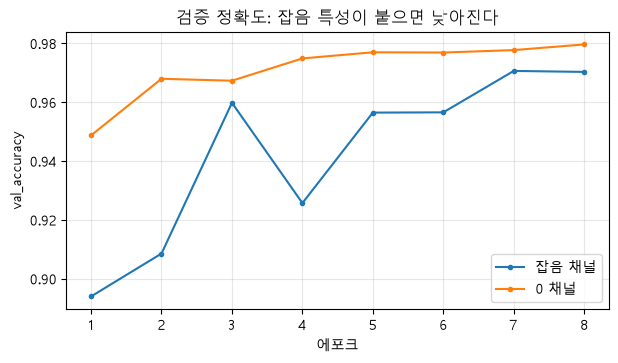

In [4]:
rng = np.random.default_rng(0)
train_images_with_noise = np.concatenate(
    [train_images, rng.random((len(train_images), 784), dtype="float32")], axis=1)
train_images_with_zeros = np.concatenate(
    [train_images, np.zeros((len(train_images), 784), dtype="float32")], axis=1)
print(train_images_with_noise.shape, train_images_with_zeros.shape)

def get_model():
    model = keras.Sequential([
        layers.Dense(512, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="rmsprop",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

h_noise = get_model().fit(train_images_with_noise, train_labels,
                          epochs=8, batch_size=128, validation_split=0.2, verbose=0)
h_zeros = get_model().fit(train_images_with_zeros, train_labels,
                          epochs=8, batch_size=128, validation_split=0.2, verbose=0)
plot_history({"잡음 채널": h_noise, "0 채널": h_zeros}, key="val_accuracy",
             title="검증 정확도: 잡음 특성이 붙으면 낮아진다")

### 🔍 내부 들여다보기: 모델이 잡음 픽셀에도 가중치를 쓰고 있나?

첫 번째 `Dense(512)`의 커널은 `(1568, 512)` 행렬이에요. 앞 784행은 진짜 픽셀, 뒤 784행은 덧붙인 특성에 붙은 가중치예요.
행마다 가중치 크기(절댓값 평균)를 비교해 봐요.

In [5]:
m = get_model()
m.fit(train_images_with_noise, train_labels, epochs=3, batch_size=128, verbose=0)
W = keras.ops.convert_to_numpy(m.layers[0].kernel)     # (1568, 512)
print("커널 shape:", W.shape)
real, noise = np.abs(W[:784]).mean(), np.abs(W[784:]).mean()
print(f"진짜 픽셀 행 |W| 평균 = {real:.4f}")
print(f"잡음 특성 행 |W| 평균 = {noise:.4f}  ← 0이 아님! 잡음에서도 '패턴'을 찾으려 함")

m0 = get_model()
m0.build((None, 1568))
W0_init = keras.ops.convert_to_numpy(m0.layers[0].kernel).copy()      # 훈련 전 초깃값 저장
m0.fit(train_images_with_zeros, train_labels, epochs=3, batch_size=128, verbose=0)
W0 = keras.ops.convert_to_numpy(m0.layers[0].kernel)
print(f"0 특성 행: 훈련 전후 최대 변화량 = {np.abs(W0[784:] - W0_init[784:]).max():.6f}  ← 0! (입력이 0이면 그레이디언트도 0)")
print(f"진짜 픽셀 행: 훈련 전후 최대 변화량 = {np.abs(W0[:784] - W0_init[:784]).max():.4f}")

커널 shape: (1568, 512)
진짜 픽셀 행 |W| 평균 = 0.0360
잡음 특성 행 |W| 평균 = 0.0275  ← 0이 아님! 잡음에서도 '패턴'을 찾으려 함
0 특성 행: 훈련 전후 최대 변화량 = 0.000000  ← 0! (입력이 0이면 그레이디언트도 0)
진짜 픽셀 행: 훈련 전후 최대 변화량 = 0.3519

💬 **설명 포인트**: 0 채널의 가중치는 왜 훈련해도 안 바뀔까?

> `Dense`의 커널 그레이디언트 = `입력ᵀ · (출력 쪽 그레이디언트)`. 입력이 0이면 그 행의 그레이디언트도 0 → 업데이트가 없어요.
> 반면 잡음 입력은 0이 아니라서, 모델이 잡음과 레이블 사이의 **우연한 상관관계**까지 외우려 해요 → 과대적합.

## 2. 레이블을 섞어도 훈련 정확도는 오른다 (§5.1.1)

레이블을 무작위로 섞으면 입력과 정답 사이에 **아무 관계가 없어요**.
그래도 모델이 충분히 크면 훈련 데이터를 **외워 버려요**. 검증 정확도는 10%(찍기) 그대로예요.

(시간을 아끼려고 훈련 샘플 1만 개만 써요.)

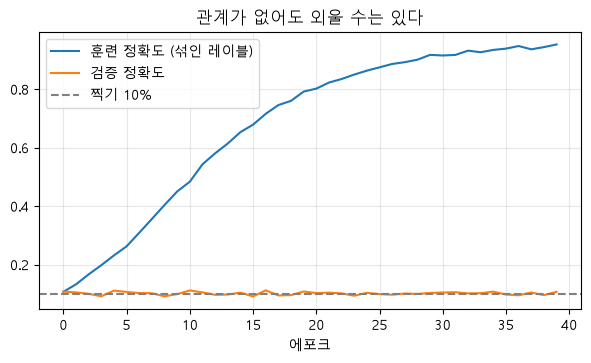

마지막 훈련 정확도: 0.953

In [6]:
n = 10000
random_labels = train_labels[:n].copy()
np.random.default_rng(1).shuffle(random_labels)

model = keras.Sequential([
    layers.Dense(512, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_rand = model.fit(train_images[:n], random_labels, epochs=40, batch_size=128,
                   validation_split=0.2, verbose=0)

plt.figure(figsize=(7, 3.6))
plt.plot(h_rand.history["accuracy"], label="훈련 정확도 (섞인 레이블)")
plt.plot(h_rand.history["val_accuracy"], label="검증 정확도")
plt.axhline(0.1, ls="--", c="gray", label="찍기 10%")
plt.xlabel("에포크"); plt.legend(); plt.grid(alpha=.3)
plt.title("관계가 없어도 외울 수는 있다"); plt.show()
print("마지막 훈련 정확도:", round(h_rand.history["accuracy"][-1], 3))

💬 **설명 포인트**: 그럼 "훈련 정확도가 높다"는 무엇을 증명하지?

> 아무것도요. 훈련 성능은 **외운 양**일 수도 있어요. 그래서 일반화는 항상 **처음 보는 데이터**(검증 · 테스트)로 재요.
> 파라미터 수 ≈ 66만 개 > 샘플 8천 개 → 샘플마다 '자리'를 하나씩 줄 만큼 용량이 넉넉해요.

## 3. 매니폴드 가설: 두 숫자의 '평균'은 숫자가 아니다 (§5.1.2)

- 784차원 픽셀 공간에서 **아무 점이나 찍으면** 잡음이에요 → 공간 대부분은 '숫자가 아닌' 빈 공간.
- 진짜 숫자들은 그 안의 **얇은 곡면(매니폴드)** 위에 모여 있어요.
- 픽셀 공간에서 두 숫자를 직선으로 섞으면(평균) 곡면을 **벗어나서** 겹친 유령 이미지가 돼요.
- 딥러닝이 잘하는 건 곡면 **위에서의** 보간이에요.

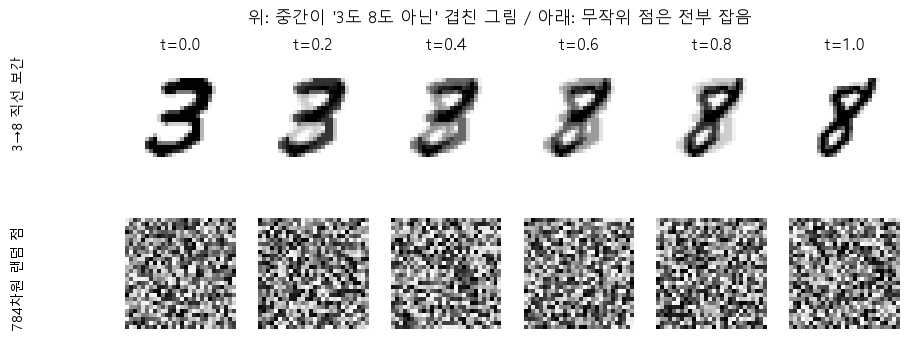

In [7]:
a = train_images[train_labels == 3][0]
b = train_images[train_labels == 8][0]
ts = np.linspace(0, 1, 6)

fig, axes = plt.subplots(2, 6, figsize=(10, 3.8))
for ax, t in zip(axes[0], ts):
    ax.imshow(((1 - t) * a + t * b).reshape(28, 28), cmap="gray_r"); ax.set_title(f"t={t:.1f}"); ax.axis("off")
rng = np.random.default_rng(3)
for ax in axes[1]:
    ax.imshow(rng.random(784).reshape(28, 28), cmap="gray_r"); ax.axis("off")
axes[0, 0].set_ylabel("픽셀 공간 보간")
fig.text(0.01, 0.73, "3→8 직선 보간", rotation=90, va="center")
fig.text(0.01, 0.27, "784차원 랜덤 점", rotation=90, va="center")
plt.suptitle("위: 중간이 '3도 8도 아닌' 겹친 그림 / 아래: 무작위 점은 전부 잡음"); plt.show()

### 🔍 내부 들여다보기: 진짜 숫자들은 784차원 중 몇 차원을 쓰나?

PCA(주성분 분석)로 분산의 90%를 설명하려면 성분이 몇 개 필요한지 세 봐요. 784보다 훨씬 작다면 → 데이터가 저차원 구조 위에 있다는 증거예요.

In [8]:
X = train_images[:5000] - train_images[:5000].mean(axis=0)
s = np.linalg.svd(X, compute_uv=False)
ratio = np.cumsum(s ** 2) / np.sum(s ** 2)
for p in (0.5, 0.8, 0.9, 0.95):
    print(f"분산 {int(p*100)}% 설명에 필요한 차원: {np.searchsorted(ratio, p) + 1:4d} / 784")

Xr = rng.random((5000, 784)); Xr -= Xr.mean(axis=0)
sr = np.linalg.svd(Xr, compute_uv=False); rr = np.cumsum(sr ** 2) / np.sum(sr ** 2)
print(f"(비교) 랜덤 잡음은 90%에 {np.searchsorted(rr, 0.9) + 1}차원 필요")

분산 50% 설명에 필요한 차원:   11 / 784
분산 80% 설명에 필요한 차원:   43 / 784
분산 90% 설명에 필요한 차원:   84 / 784
분산 95% 설명에 필요한 차원:  148 / 784
(비교) 랜덤 잡음은 90%에 629차원 필요

## 4. 평가 방법 (§5.2)

| 방법 | 언제 | 핵심 |
|---|---|---|
| 홀드아웃 | 데이터가 많을 때 | 섞고 → 검증 몫을 떼어 둠 |
| K-겹 | 데이터가 적을 때 | K번 돌려서 점수 평균 (4장 주택 가격) |
| 반복 K-겹 | 아주 적고 정밀해야 할 때 | 섞어서 K-겹을 여러 번 |

⚠️ 주의 3가지: **대표성**(섞기) · **시간 방향**(미래로 과거 예측 X) · **중복 샘플**(훈련 · 검증에 같은 샘플 X)

In [9]:
# 홀드아웃: 섞은 다음 앞쪽을 검증으로
num_validation = 10000
idx = np.random.default_rng(0).permutation(len(train_images))
val_idx, tr_idx = idx[:num_validation], idx[num_validation:]
print("훈련", len(tr_idx), "/ 검증", len(val_idx))

# 섞지 않으면? 클래스 분포가 치우쳤는지 확인 (MNIST는 이미 섞여 있지만, 정렬된 데이터라면 큰일)
sorted_labels = np.sort(train_labels)
print("정렬된 데이터의 마지막 10000개 클래스:", np.unique(sorted_labels[-10000:]))

훈련 50000 / 검증 10000
정렬된 데이터의 마지막 10000개 클래스: [8 9]

In [10]:
# K-겹 인덱스가 어떻게 나뉘는지 눈으로 (샘플 12개, K=3)
k, N = 3, 12
folds = np.array_split(np.arange(N), k)
for i in range(k):
    val = folds[i]
    train = np.concatenate([folds[j] for j in range(k) if j != i])
    print(f"라운드 {i+1}: 검증 {val.tolist()}  훈련 {train.tolist()}")

라운드 1: 검증 [0, 1, 2, 3]  훈련 [4, 5, 6, 7, 8, 9, 10, 11]
라운드 2: 검증 [4, 5, 6, 7]  훈련 [0, 1, 2, 3, 8, 9, 10, 11]
라운드 3: 검증 [8, 9, 10, 11]  훈련 [0, 1, 2, 3, 4, 5, 6, 7]

### 상식 수준의 기준점 (common-sense baseline)

모델을 만들기 전에 '아무 생각 없이 찍었을 때' 점수부터 알아야 해요. 이걸 못 넘으면 모델이 아무것도 못 배운 거예요.

In [11]:
counts = np.bincount(train_labels)
print("클래스별 개수:", counts.tolist())
print(f"가장 많은 클래스만 찍기 정확도 = {counts.max() / counts.sum():.3f}")
print("→ MNIST 기준점은 약 11%. 98%짜리 모델은 이걸 크게 넘은 것")

클래스별 개수: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
가장 많은 클래스만 찍기 정확도 = 0.112
→ MNIST 기준점은 약 11%. 98%짜리 모델은 이걸 크게 넘은 것

### 🔍 정보 누설: 정규화 통계를 어디서 계산하나

평균 · 표준편차를 **검증 · 테스트까지 합쳐서** 구하면, 모델이 검증 데이터 정보를 미리 본 셈이에요.
항상 **훈련 데이터로만** 계산하고 같은 값을 검증 · 테스트에 적용해요.

In [12]:
x_tr, x_val = train_images[tr_idx], train_images[val_idx]
mean, std = x_tr.mean(), x_tr.std()            # ✅ 훈련 데이터로만 (이미지는 픽셀 전체를 한 묶음으로)
x_tr_n, x_val_n = (x_tr - mean) / std, (x_val - mean) / std
print(f"훈련 통계: 평균 {mean:.4f}, 표준편차 {std:.4f}")
print("정규화 후 훈련 평균 ≈", x_tr_n.mean().round(4), "/ 검증 평균 =", x_val_n.mean().round(4), "← 0 근처지만 정확히 0은 아님 (정상)")
print("⚠️ 픽셀마다 따로 표준편차를 쓰면, 훈련에서 늘 0이던 가장자리 픽셀이 검증에서 값이 있을 때 ÷0에 가까워져 폭발해요")

훈련 통계: 평균 0.1306, 표준편차 0.3081
정규화 후 훈련 평균 ≈ -0.0 / 검증 평균 = 0.0006 ← 0 근처지만 정확히 0은 아님 (정상)
⚠️ 픽셀마다 따로 표준편차를 쓰면, 훈련에서 늘 0이던 가장자리 픽셀이 검증에서 값이 있을 때 ÷0에 가까워져 폭발해요

## 5. 훈련 성능 향상: 증상 → 처방 (§5.3)

| 증상 | 처방 |
|---|---|
| 손실이 안 내려감 | 학습률 · 배치 크기 조정 |
| 기준점을 못 넘음 | 입력에 정보가 부족한지 의심 |
| 과대적합이 **안 됨** | 모델 용량(층 · 유닛) 키우기 |

### 5-1. 학습률이 너무 크면

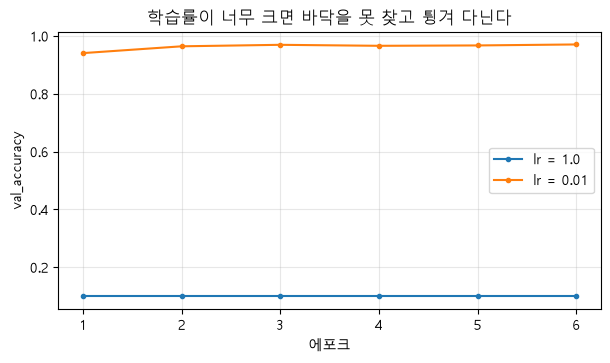

In [13]:
def mnist_model(lr):
    m = keras.Sequential([layers.Dense(512, activation="relu"), layers.Dense(10, activation="softmax")])
    m.compile(optimizer=keras.optimizers.RMSprop(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

h_big = mnist_model(1.0).fit(train_images, train_labels, epochs=6, batch_size=128, validation_split=0.2, verbose=0)
h_ok = mnist_model(1e-2).fit(train_images, train_labels, epochs=6, batch_size=128, validation_split=0.2, verbose=0)
plot_history({"lr = 1.0": h_big, "lr = 0.01": h_ok}, key="val_accuracy", title="학습률이 너무 크면 바닥을 못 찾고 튕겨 다닌다")

💬 **설명 포인트**: 2장 경사 하강법 그림에서 '한 걸음'의 크기가 학습률이에요. 너무 크면 골짜기를 건너뛰어 반대편 벽에 부딪혀요.

### 5-2. 모델이 너무 작으면 과대적합조차 못 한다

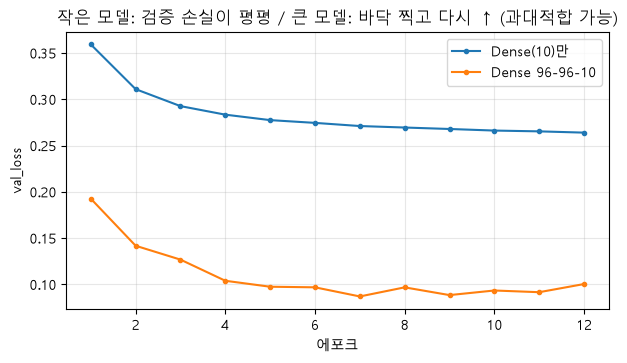

파라미터 수: 7850 vs 85642

In [14]:
small = keras.Sequential([layers.Dense(10, activation="softmax")])          # 로지스틱 회귀
small.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_small = small.fit(train_images, train_labels, epochs=12, batch_size=128, validation_split=0.2, verbose=0)

large = keras.Sequential([layers.Dense(96, activation="relu"), layers.Dense(96, activation="relu"),
                          layers.Dense(10, activation="softmax")])
large.compile(optimizer="rmsprop", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_large = large.fit(train_images, train_labels, epochs=12, batch_size=128, validation_split=0.2, verbose=0)

plot_history({"Dense(10)만": h_small, "Dense 96-96-10": h_large}, key="val_loss",
             title="작은 모델: 검증 손실이 평평 / 큰 모델: 바닥 찍고 다시 ↑ (과대적합 가능)")
print("파라미터 수:", small.count_params(), "vs", large.count_params())

💬 **설명 포인트**: 1단계 목표가 왜 '과대적합할 수 있는 모델'일까?

> 과대적합이 일어나는 지점을 봐야 **용량의 경계**를 알 수 있어요. 경계를 안 다음에 규제로 끌어내리는 게 순서예요 (5.4).

## 6. 일반화 성능 향상: 규제 (§5.4) — IMDB

4장의 영화 리뷰 이진 분류 모델(Dense 16-16-1)을 기준으로 네 가지를 비교해요.

| 모델 | 바꾼 것 |
|---|---|
| 원본 | Dense 16 · 16 |
| 작은 모델 | Dense 4 · 4 (용량 ↓) |
| L2 | 원본 + `kernel_regularizer=l2(0.002)` |
| 드롭아웃 | 원본 + `Dropout(0.5)` 두 개 |

In [15]:
from keras.datasets import imdb

(x_imdb, y_imdb), _ = imdb.load_data(num_words=10000)

def multi_hot(seqs, dim=10000):
    out = np.zeros((len(seqs), dim), dtype="float32")
    for i, s in enumerate(seqs):
        out[i, s] = 1.0
    return out

x_imdb = multi_hot(x_imdb); y_imdb = y_imdb.astype("float32").reshape(-1, 1)   # (N, 1): 출력 shape과 맞춤
print(x_imdb.shape, "| 리뷰 하나에 켜진 단어 수 평균:", x_imdb.sum(axis=1).mean().round(1))

(25000, 10000) | 리뷰 하나에 켜진 단어 수 평균: 131.7

원본     최저 검증 BCE 0.276 (에포크 4) / 마지막 0.453 | 최고 검증 정확도 0.891
작은 모델  최저 검증 BCE 0.442 (에포크 14) / 마지막 0.459 | 최고 검증 정확도 0.875
L2     최저 검증 BCE 0.282 (에포크 6) / 마지막 0.411 | 최고 검증 정확도 0.886
드롭아웃   최저 검증 BCE 0.273 (에포크 6) / 마지막 0.436 | 최고 검증 정확도 0.892

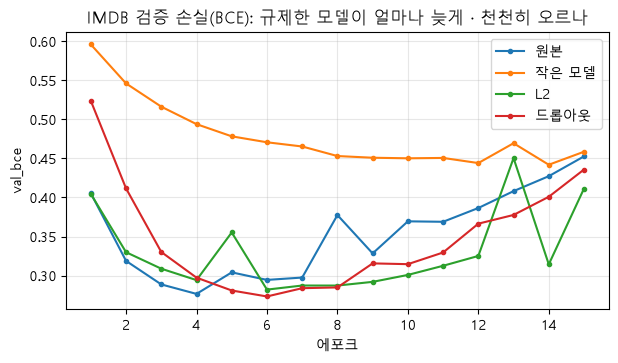

In [16]:
from keras import regularizers

def imdb_model(kind):
    reg = regularizers.l2(0.002) if kind == "L2" else None
    units = 4 if kind == "작은 모델" else 16
    model = keras.Sequential([keras.Input(shape=(10000,))])
    for _ in range(2):
        model.add(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if kind == "드롭아웃":
            model.add(layers.Dropout(0.5))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer="rmsprop", loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.BinaryCrossentropy(name="bce")])   # 벌점 없는 순수 손실
    return model

hist, models = {}, {}
for kind in ["원본", "작은 모델", "L2", "드롭아웃"]:
    models[kind] = imdb_model(kind)
    hist[kind] = models[kind].fit(x_imdb, y_imdb, epochs=15, batch_size=512, validation_split=0.4, verbose=0)
    v = hist[kind].history["val_bce"]
    print(f"{kind:6s} 최저 검증 BCE {min(v):.3f} (에포크 {int(np.argmin(v)) + 1}) / 마지막 {v[-1]:.3f} | "
          f"최고 검증 정확도 {max(hist[kind].history['val_accuracy']):.3f}")

plot_history(hist, key="val_bce", title="IMDB 검증 손실(BCE): 규제한 모델이 얼마나 늦게 · 천천히 오르나")

⚠️ 그래프는 `val_loss`가 아니라 지표 `val_bce`를 그려요. L2 모델의 `loss`에는 아래 ①의 **벌점이 더해져 있어서**, `val_loss`로 비교하면 L2가 불공평하게 나빠 보여요.

💬 **설명 포인트**: 결과가 책 그림과 똑같지 않다면? 규제 강도(0.002), 에포크, 데이터 분할에 따라 달라져요. 핵심은 **최저점 이후 곡선이 오르는 기울기**를 비교하는 거예요.

### 🔍 내부 들여다보기 ① L2 규제는 손실에 무엇을 더하나

`model.losses`에 **가중치 벌점** 항이 들어 있어요. 훈련 손실 = `binary_crossentropy` + 이 벌점이에요.
벌점 = `0.002 × Σ W²` (층마다).

In [17]:
m = models["L2"]
penalties = [float(keras.ops.convert_to_numpy(l)) for l in m.losses]
print("층별 L2 벌점:", [round(p, 4) for p in penalties])

k0 = keras.ops.convert_to_numpy(m.layers[0].kernel)
print("직접 계산 0.002 × ΣW² =", round(0.002 * float((k0 ** 2).sum()), 4), "← 첫 번째 값과 같아요")

for kind in ["원본", "L2"]:
    k = keras.ops.convert_to_numpy(models[kind].layers[0].kernel)
    print(f"{kind:3s} 첫 층 가중치 |W| 평균 = {np.abs(k).mean():.4f}")
print("→ L2는 가중치를 0 '쪽으로' 작게 만든다 (L1은 아예 0으로 만들어 희소하게)")

층별 L2 벌점: [0.0585, 0.0293]
직접 계산 0.002 × ΣW² = 0.0585 ← 첫 번째 값과 같아요
원본  첫 층 가중치 |W| 평균 = 0.0240
L2  첫 층 가중치 |W| 평균 = 0.0094
→ L2는 가중치를 0 '쪽으로' 작게 만든다 (L1은 아예 0으로 만들어 희소하게)

### 🔍 내부 들여다보기 ② 드롭아웃은 훈련 때만 켜진다

`Dropout(0.5)`는 훈련 때 절반을 0으로 만들고, 남은 값은 **÷(1−0.5) = ×2** 해서 전체 합(기댓값)을 맞춰요.
추론 때(`training=False`)는 아무것도 안 해요.

In [18]:
drop = layers.Dropout(0.5, seed=7)
x = np.ones((1, 10), dtype="float32")
print("training=True :", keras.ops.convert_to_numpy(drop(x, training=True)))
print("training=False:", keras.ops.convert_to_numpy(drop(x, training=False)))

training=True : [[2. 2. 0. 0. 2. 2. 2. 0. 0. 0.]]
training=False: [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]

💬 **설명 포인트**: 드롭아웃이 왜 과대적합을 줄일까?

> 매 배치마다 다른 뉴런 조합으로 예측해야 해서, 특정 뉴런들의 **우연한 협업 패턴**(= 외운 것)에 기대지 못해요. 힌턴의 비유: 은행 직원을 자주 바꾸면 공모하기 어렵다.

---
## 정리 · 스스로 설명해 보기

1. 훈련 손실은 내려가는데 검증 손실이 오르면? → ______
2. 레이블을 섞어도 훈련 정확도가 오르는 이유는? → ______
3. 정규화 평균 · 표준편차는 어느 데이터로 계산하나? → ______
4. 과대적합이 아예 안 되는 모델에 먼저 할 일은? → ______
5. L1과 L2의 차이를 그림 노트 표현으로 한 줄씩 → ______